In [16]:
from pytom_tm.tmjob import TMJob
from pytom_tm.parallel import run_job_parallel
from pathlib import Path
import numpy as np
import mrcfile
from skimage.feature import peak_local_max
from matplotlib import pyplot as plt
import torch.nn.functional as F
import torch
import einops
from torch_subpixel_crop.dft_utils import dft_center
from torch_subpixel_crop import subpixel_crop_3d
import torch.nn as nn
import torch.optim as optim
import starfile
import pandas as pd

In [29]:
tomograms = [
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_7/patch_tracking/20240621_15F1Fab-AuNP_7_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_8/patch_tracking/20240621_15F1Fab-AuNP_8_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_9/patch_tracking/20240621_15F1Fab-AuNP_9_full_rec_BP_flat.mrc")
]
template = Path("/groups/elferich/Documents/findingampa/temaplte.mrc")
mask = Path("/groups/elferich/Documents/findingampa/mask.mrc")
angles = Path("/groups/elferich/Documents/findingampa/angles.txt")

In [44]:
def calc_3dtm(tomo):
    job = TMJob(
        "0",
        20,
        tomo,
        template,
        mask,
        Path('./'),
        angle_increment=str(angles),
        mask_is_spherical=True,
        tilt_angles=[-48,48],
        tilt_weighting=None,
        search_x=None,
        search_y=None,
        search_z=None,
        tomogram_mask=None,
        voxel_size=10.0,
        low_pass=None,
        high_pass=None,
        dose_accumulation=None,
        ctf_data=None,
        whiten_spectrum=True,
        rotational_symmetry=1,
        particle_diameter=None,
        random_phase_correction=False,
        rng_seed=5,
    )

    score_volume, angle_volume = run_job_parallel(
        job, (2,2,2), [0]
    )
    mrcfile.write(f"/scratch/pompeii/elferich/gouaux_tomo/ProcessingJE/AuNP_TM/{tomo.name.removesuffix('.mrc')}_score.mrc", score_volume.T, overwrite=True, voxel_size=10.0)
    peaks = peak_local_max(score_volume, min_distance=2, threshold_abs=0.3, exclude_border=10)

    locations_tomo = torch.Tensor(peaks[:,::-1].copy()+ np.array([0,0,0])) # FRom XYZ to ZYX
    return locations_tomo, torch.Tensor(peaks).int(), score_volume

class Gaussian3DList(nn.Module):
    def __init__(self, num_gaussians,sign=1):
        super(Gaussian3DList, self).__init__()
        self.amplitude = nn.Parameter(torch.ones(num_gaussians)*sign)
        self.x0 = nn.Parameter(torch.zeros(num_gaussians))
        self.y0 = nn.Parameter(torch.zeros(num_gaussians))
        self.z0 = nn.Parameter(torch.zeros(num_gaussians))
        self.sigma_x = nn.Parameter(torch.ones(num_gaussians))
        self.sigma_y = nn.Parameter(torch.ones(num_gaussians))
        self.sigma_z = nn.Parameter(torch.ones(num_gaussians))

    def forward(self, x, y, z):
        
        x = x.unsqueeze(0)  # Shape: (num_points, num_gaussians)
        y = y.unsqueeze(0)
        z = z.unsqueeze(0)
        return self.amplitude.unsqueeze(1) * torch.exp(
            -((x - self.x0.unsqueeze(1)) ** 2 / (2 * self.sigma_x.unsqueeze(1) ** 2) +
              (y - self.y0.unsqueeze(1)) ** 2 / (2 * self.sigma_y.unsqueeze(1) ** 2) +
              (z - self.z0.unsqueeze(1)) ** 2 / (2 * self.sigma_z.unsqueeze(1) ** 2))
        )  # Sum over the gaussians

def fit_gaussian_3d_list(score_volume, locations, boxsize, sign=1):
    num_gaussians = len(locations)
    model = Gaussian3DList(num_gaussians,sign=sign).to(score_volume.device)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    # Prepare the 4D tensor of boxes
    boxes = []
    for loc in locations:
        x, y, z = loc
        region = score_volume[x-boxsize//2:x+boxsize//2+1, y-boxsize//2:y+boxsize//2+1, z-boxsize//2:z+boxsize//2+1]
        
        boxes.append(region)
    boxes = torch.stack(boxes).to(score_volume.device)  # Shape: (num_gaussians, boxsize, boxsize, boxsize)

    # Prepare the coordinates
    coords = torch.stack(torch.meshgrid(
        torch.arange(boxsize+1),
        torch.arange(boxsize+1),
        torch.arange(boxsize+1)
    ), dim=-1).reshape(-1, 3).to(score_volume.device) - torch.tensor([boxsize//2, boxsize//2, boxsize//2], device=score_volume.device)
    x_coords = coords[:, 0].float()
    y_coords = coords[:, 1].float()
    z_coords = coords[:, 2].float()

    for _ in range(1000):  # Number of iterations
        optimizer.zero_grad()
        output = model(x_coords, y_coords, z_coords).reshape(num_gaussians, boxsize+1, boxsize+1, boxsize+1)
        loss = criterion(output, boxes)
        loss.backward()
        optimizer.step()

    fitted_params = []
    for i in range(num_gaussians):
        fitted_params.append({
            'amplitude': model.amplitude[i].item(),
            'x0': model.x0[i].item(),
            'y0': model.y0[i].item(),
            'z0': model.z0[i].item(),
            'sigma_x': model.sigma_x[i].item(),
            'sigma_y': model.sigma_y[i].item(),
            'sigma_z': model.sigma_z[i].item(),
            'loss': loss.item()
        })

    return fitted_params

In [4]:
subtomos = []
score_fitted_params = []
tomo_fitted_params = []
subtomos_subpixel = []
for tomo in tomograms:
    locations_tomo, locations_score_volume, score_volume = calc_3dtm(tomo)
    score_volume = torch.tensor(score_volume).cuda()
    fitted_params_list = fit_gaussian_3d_list(torch.tensor(score_volume), locations_score_volume.cuda(),6)
    score_fitted_params.append(fitted_params_list)
    offsets = torch.tensor([[f['x0'], f['y0'], f['z0']] for f in fitted_params_list])
    with mrcfile.open(tomo, permissive=True) as f:
        tomo_tensor = torch.tensor(f.data)
    print(locations_tomo.shape)
    print(offsets.shape)
    print(offsets.sum(dim=0))
    subtomos.append(subpixel_crop_3d(tomo_tensor, locations_tomo, 20))
    subtomos_subpixel.append(subpixel_crop_3d(tomo_tensor, locations_tomo + offsets, 20))
    tomo_fitted_params.append(fit_gaussian_3d_list(tomo_tensor.cuda(), locations_tomo.int().cuda(), 6, sign=-1))
subtomos = torch.cat(subtomos, dim=0)
subtomos_subpixel = torch.cat(subtomos_subpixel, dim=0)
average = einops.reduce(subtomos,'s z y x -> z y x','mean')
average_subpixel = einops.reduce(subtomos_subpixel,'s z y x -> z y x','mean')

Progress job_00 on device 0:


100%|████████████████████████████████████████████| 1/1 [00:00<00:00,  2.48it/s]


Progress job_01 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1494.23it/s]


Progress job_02 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1461.43it/s]


... (39 outputs left out)

100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1536.94it/s]


Progress job_07 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1574.44it/s]


torch.Size([1683, 3])
torch.Size([1683, 3])
tensor([-17.9620,  -1.3897, -92.2308])


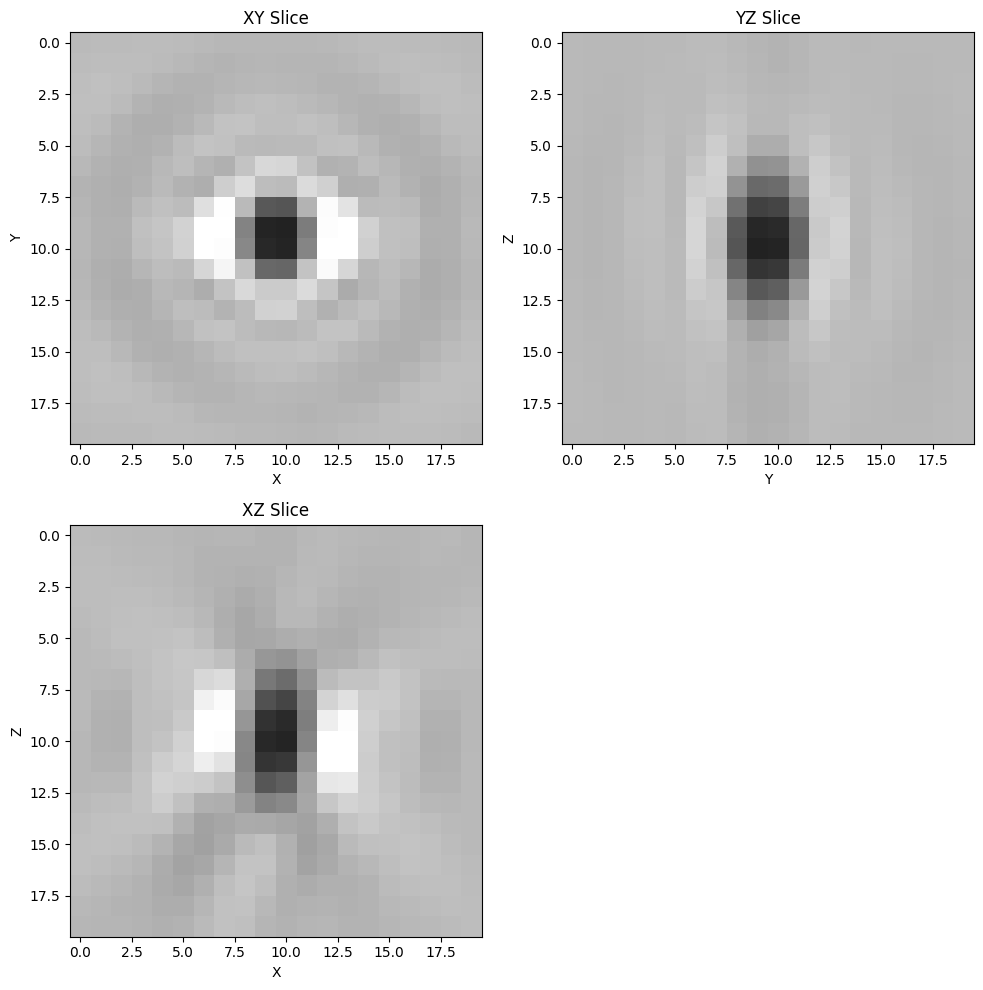

In [9]:
# Assuming `average` is your 3D array
# Plotting the slices
plt.figure(figsize=(10, 10))

# Plotting the xy slice (top left)
plt.subplot(2, 2, 1)
plt.imshow(average[average.shape[2] // 2, :, :], cmap='gray', vmin=-2.5,vmax=1.0)
plt.title('XY Slice')
plt.xlabel('X')
plt.ylabel('Y')

# Plotting the yz slice (top right)
plt.subplot(2, 2, 2)
plt.imshow(average[:, : , average.shape[1] // 2], cmap='gray', vmin=-2.5,vmax=1.0)
plt.title('YZ Slice')
plt.xlabel('Y')
plt.ylabel('Z')

# Plotting the xz slice (bottom left)
plt.subplot(2, 2, 3)
plt.imshow( average[:,average.shape[0] // 2, :], cmap='gray', vmin=-2.5,vmax=1.0)
plt.title('XZ Slice')
plt.xlabel('X')
plt.ylabel('Z')

# Adjust layout
plt.tight_layout()
plt.show()


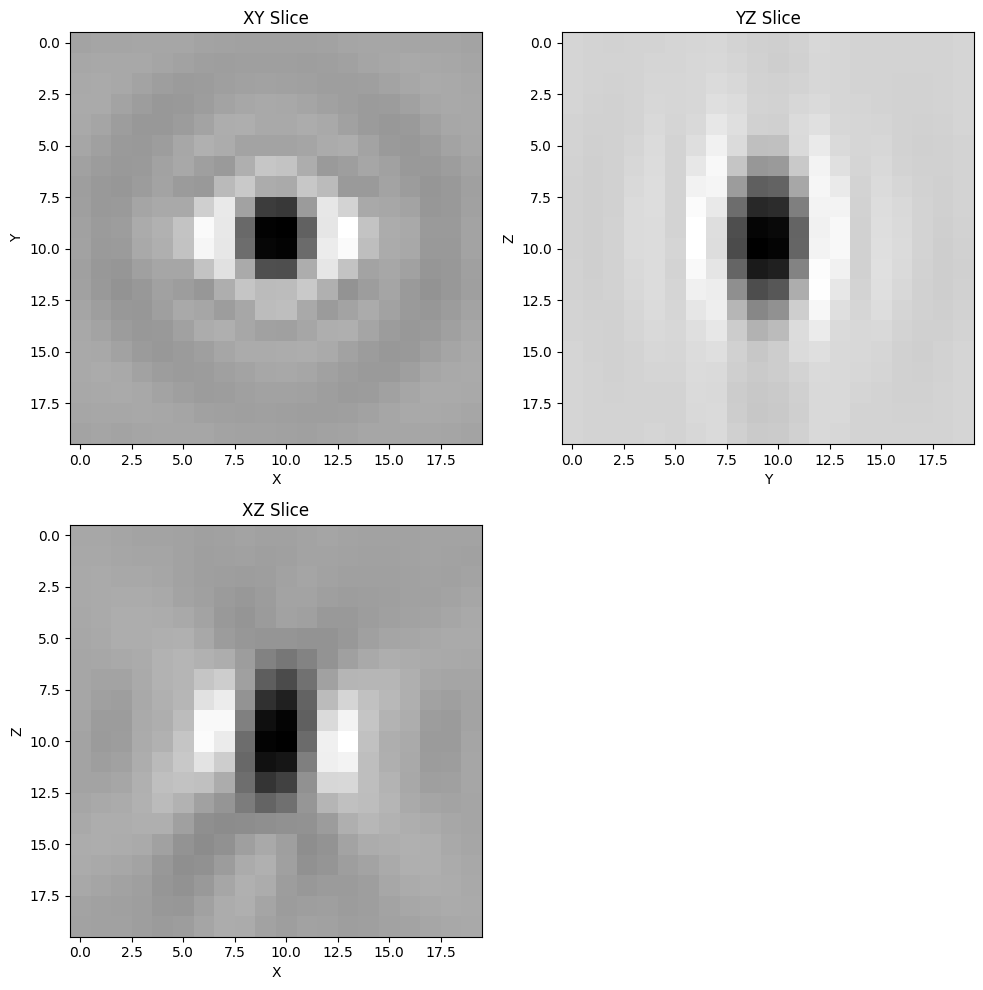

In [18]:
# Assuming `average` is your 3D array
# Plotting the slices
plt.figure(figsize=(10, 10))

# Plotting the xy slice (top left)
plt.subplot(2, 2, 1)
plt.imshow(average_subpixel[average.shape[2] // 2, :, :], cmap='gray')
plt.title('XY Slice')
plt.xlabel('X')
plt.ylabel('Y')

# Plotting the yz slice (top right)
plt.subplot(2, 2, 2)
plt.imshow(average_subpixel[:, : , average.shape[1] // 2], cmap='gray')
plt.title('YZ Slice')
plt.xlabel('Y')
plt.ylabel('Z')

# Plotting the xz slice (bottom left)
plt.subplot(2, 2, 3)
plt.imshow( average_subpixel[:,average.shape[0] // 2, :], cmap='gray')
plt.title('XZ Slice')
plt.xlabel('X')
plt.ylabel('Z')

# Adjust layout
plt.tight_layout()
plt.show()


In [24]:
score_fitted_params[0][0]

{'amplitude': 0.7952068448066711,
 'x0': 0.05847029760479927,
 'y0': 0.14924675226211548,
 'z0': -0.030766561627388,
 'sigma_x': 0.7899115085601807,
 'sigma_y': 0.9248875975608826,
 'sigma_z': 2.5997955799102783,
 'loss': 0.008760406635701656}

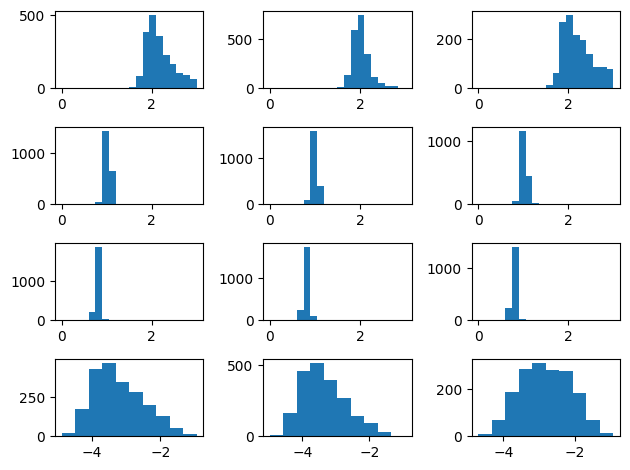

In [12]:
plt.subplot(4, 3, 1)
plt.hist([tp['sigma_x'] for tp in tomo_fitted_params[0]], bins=20, range=(0, 3))
plt.subplot(4, 3, 2)
plt.hist([tp['sigma_x'] for tp in tomo_fitted_params[1]], bins=20, range=(0, 3))
plt.subplot(4, 3, 3)
plt.hist([tp['sigma_x'] for tp in tomo_fitted_params[2]], bins=20, range=(0, 3))
plt.subplot(4, 3, 4)
plt.hist([tp['sigma_y'] for tp in tomo_fitted_params[0]], bins=20, range=(0, 3))
plt.subplot(4, 3, 5)
plt.hist([tp['sigma_y'] for tp in tomo_fitted_params[1]], bins=20, range=(0, 3))
plt.subplot(4, 3, 6)
plt.hist([tp['sigma_y'] for tp in tomo_fitted_params[2]], bins=20, range=(0, 3))
plt.subplot(4, 3, 7)
plt.hist([tp['sigma_z'] for tp in tomo_fitted_params[0]], bins=20, range=(0, 3))
plt.subplot(4, 3, 8)
plt.hist([tp['sigma_z'] for tp in tomo_fitted_params[1]], bins=20, range=(0, 3))
plt.subplot(4, 3, 9)
plt.hist([tp['sigma_z'] for tp in tomo_fitted_params[2]], bins=20, range=(0, 3))
plt.subplot(4, 3, 10)
plt.hist([tp['amplitude'] for tp in tomo_fitted_params[0]])
plt.subplot(4, 3, 11)
plt.hist([tp['amplitude'] for tp in tomo_fitted_params[1]])
plt.subplot(4, 3, 12)
plt.hist([tp['amplitude'] for tp in tomo_fitted_params[2]])
plt.tight_layout()

In [13]:
path_to_tomos = Path('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/')

In [23]:
with open('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/list_for_cryocare','r') as f:
    cryocare_tomos = f.readlines()

In [24]:
real_tomos = [list(Path(path_to_tomos / cryocare_tomo.strip()).glob('*_full_rec_BP_flat.mrc'))[0] for cryocare_tomo in cryocare_tomos]

In [25]:
real_tomos

[PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20230509_CryoProDexSucB_59/patch_tracking/20230509_CryoProDexSucB_59_full_rec_BP_flat.mrc'),
 PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20230509_CryoProDexSucB_95/patch_tracking/20230509_CryoProDexSucB_95_full_rec_BP_flat.mrc'),
 PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20231017_EGmilled24-2_54/patch_tracking/20231017_EGmilled24-2_54_full_rec_BP_flat.mrc'),
 PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20231017_EGmilled24-2_57/patch_tracking/20231017_EGmilled24-2_57_full_rec_BP_flat.mrc'),
 PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20231017_EGmilled24-2_60/patch_tracking/20231017_EGmilled24-2_60_full_rec_BP_flat.mrc'),
 PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomogram

In [46]:
real_subtomos = []
real_score_fitted_params = []
real_tomo_fitted_params = []
real_subtomos_subpixel = []
real_locations_tomo = []
for tomo in real_tomos:

    locations_tomo, locations_score_volume, score_volume = calc_3dtm(tomo)
    real_locations_tomo.append(locations_tomo)
    score_volume = torch.tensor(score_volume).cuda()
    fitted_params_list = fit_gaussian_3d_list(torch.tensor(score_volume), locations_score_volume.cuda(),6)
    real_score_fitted_params.append(fitted_params_list)
    offsets = torch.tensor([[f['x0'], f['y0'], f['z0']] for f in fitted_params_list])
    with mrcfile.open(tomo, permissive=True) as f:
        tomo_tensor = torch.tensor(f.data)

    real_subtomos.append(subpixel_crop_3d(tomo_tensor, locations_tomo, 20))
    real_subtomos_subpixel.append(subpixel_crop_3d(tomo_tensor, locations_tomo + offsets, 20))
    real_tomo_fitted_params.append(fit_gaussian_3d_list(tomo_tensor.cuda(), locations_tomo.int().cuda(), 6, sign=-1))
    data = pd.DataFrame({'faTM_PeakX':locations_tomo[:,2].cpu().numpy(),
                         'faTM_PeakY':locations_tomo[:,1].cpu().numpy(),
                         'faTM_PeakZ':locations_tomo[:,0].cpu().numpy(),
                         'faTM_PeakScore':[score_volume[x,y,z].item() for x,y,z in locations_score_volume],
                         'faTM_gaussianFitX':offsets[:,0].cpu().numpy(),
                         'faTM_gaussianFitY':offsets[:,1].cpu().numpy(),
                         'faTM_gaussianFitZ':offsets[:,2].cpu().numpy(),
                         'faTM_gaussianFitSigmaX':[f['sigma_x'] for f in fitted_params_list],
                         'faTM_gaussianFitSigmaY':[f['sigma_y'] for f in fitted_params_list],
                         'faTM_gaussianFitSigmaZ':[f['sigma_z'] for f in fitted_params_list],
                         'faTM_gaussianFitAmplitude':[f['amplitude'] for f in fitted_params_list],
                         'faTomo_gaussianFitX':[f['z0'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitY':[f['y0'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitZ':[f['x0'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitSigmaX':[f['sigma_z'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitSigmaY':[f['sigma_y'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitSigmaZ':[f['sigma_x'] for f in real_tomo_fitted_params[-1]],
                         'faTomo_gaussianFitAmplitude':[f['amplitude'] for f in real_tomo_fitted_params[-1]]})
    starfile.write(data,f"/scratch/pompeii/elferich/gouaux_tomo/ProcessingJE/AuNP_TM/{tomo.name.removesuffix('.mrc')}.star")
#subtomos = torch.cat(subtomos, dim=0)
#subtomos_subpixel = torch.cat(subtomos_subpixel, dim=0)
#average = einops.reduce(subtomos,'s z y x -> z y x','mean')
#average_subpixel = einops.reduce(subtomos_subpixel,'s z y x -> z y x','mean')

Progress job_00 on device 0:


100%|████████████████████████████████████████████| 1/1 [00:00<00:00,  9.18it/s]


Progress job_01 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1343.04it/s]


Progress job_02 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1466.54it/s]


... (502 outputs left out)

Progress job_06 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1489.98it/s]


Progress job_07 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1560.96it/s]


In [54]:
real_tomo_fitted_params[0][80]

{'amplitude': -7.71160364151001,
 'x0': -1.668368935585022,
 'y0': -0.9442571401596069,
 'z0': -0.6788347363471985,
 'sigma_x': 3.7762398719787598,
 'sigma_y': 1.2712185382843018,
 'sigma_z': 0.6532366275787354,
 'loss': 3.2112550735473633}

In [48]:
real_tomos[0]

PosixPath('/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/15F1_tomograms/top32/20240209_waffleHip_155/fiducial_tracking/20240209_waffleHip_155_full_rec_BP_flat.mrc')

In [53]:
real_locations_tomo[0][80]

tensor([194., 427., 309.])

In [58]:
tomo_tensor.mean()

tensor(0.0249)